In [129]:
import autograd.numpy as anp
from autograd import value_and_grad
import nlopt
import matplotlib.pyplot as plt
import problems
import topo_api
import pulp
import autograd


def run_mma_visual(env, max_iterations=50, refresh_every=1):
    nely, nelx = env.args['nely'], env.args['nelx']

    x0 = (anp.ones((nely * nelx)) * 0.3).ravel().astype(anp.float64)

    losses = []
    frames = [x0.copy()]

    # Interactive plot
    plt.ion()
    fig, ax = plt.subplots()
    im = ax.imshow(env.reshape(frames[0]), cmap='viridis', origin='lower', vmin=0, vmax=1)
    fig.colorbar(im, ax=ax)


    def mapping(z):
        return z

    def wrap_autograd_func(func, losses=None, frames=None):
        def wrapper(x, grad):
            def mapped_func(x):
                x_mapped = mapping(x)
                return func(x_mapped)
            value, g = autograd.value_and_grad(mapped_func)(x)
            if grad.size > 0:
                grad[:] = g.ravel()
            if losses is not None:
                losses.append(value)
            if frames is not None:
                frames.append(x.copy())
            return value
        return wrapper


    # Define objective and constraint
    objective_fn = lambda x: env.objective(x, volume_constraint=False)
    constraint_fn = lambda x: env.constraint(x)

    opt = nlopt.opt(nlopt.LD_MMA, x0.size)
    opt.set_lower_bounds(0.0)
    opt.set_upper_bounds(1.0)
    opt.set_min_objective(wrap_autograd_func(objective_fn, losses, frames))
    opt.add_inequality_constraint(wrap_autograd_func(constraint_fn), 1e-8)
    opt.set_maxeval(max_iterations)
    opt.set_xtol_rel(1e-6)
    opt.set_xtol_abs(1e-8)


    x_opt = opt.optimize(x0)  # start optimization from a transformed design variable

    for i, x in enumerate(frames[1:], start=1):
        x_mapped = mapping(x)
        im.set_data(env.reshape(x_mapped))
        
        ax.set_title(f"MMA iteration: {i+1}, loss: {losses[i-1]:.6f}")
        plt.pause(0.01)

    plt.ioff()
    plt.show()

    designs = [env.reshape(f) for f in frames]
    return losses, designs


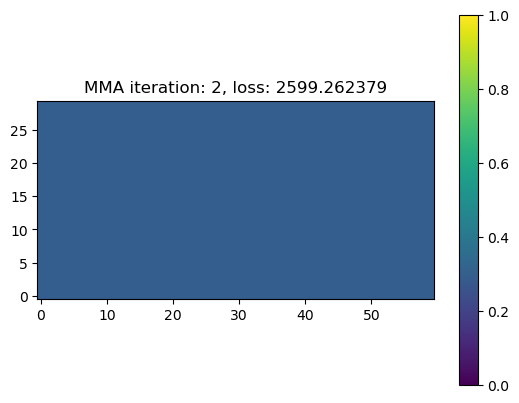

In [130]:
# =========================
# Main
# =========================

# problem = problems.example(height=80, width=120)
problem = problems.example(height=30, width=60)
args = topo_api.specified_task(problem)
env = topo_api.Environment(args)

losses, designs = run_mma_visual(env)

In [131]:
design = designs[-1]
threshold = 0.85
binary_design = (design >= threshold).astype(anp.float64)

distance = 10
fixed_mask = anp.zeros_like(binary_design)
fixed_mask[16, 59] = 1
fixed_mask[0, 0] = 1
fixed_mask[29, 0] = 1
# fixed_mask[79, 0] = 1
fixed_points = anp.argwhere(fixed_mask > 0)

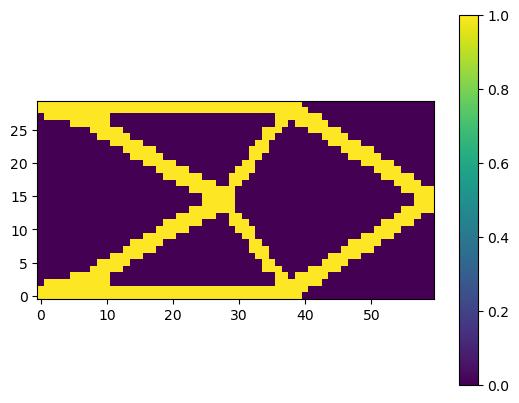

In [132]:
plt.ion()
fig, ax = plt.subplots()
im = ax.imshow(env.reshape(binary_design), cmap='viridis', origin='lower', vmin=0, vmax=1)
fig.colorbar(im, ax=ax)
plt.ioff()
plt.show()

In [133]:
import cv2
import numpy as np

def count_components_and_holes(binary_img):
    img = (binary_img > 0).astype(np.uint8) * 255
    contours, hierarchy = cv2.findContours(img, cv2.RETR_CCOMP, cv2.CHAIN_APPROX_SIMPLE)
    
    n_objects = 0
    n_holes = 0
    if hierarchy is not None:
        for i in range(len(contours)):
            if hierarchy[0, i, 3] == -1:
                n_objects += 1
            else:
                n_holes += 1
    return n_objects, n_holes

def topological_shrink_fixed(binary_design, fixed_mask=None, iterations=1):
    design = (binary_design > 0).astype(np.uint8) * 255
    if fixed_mask is None:
        fixed_mask = np.zeros_like(design, dtype=np.uint8)
    kernel = np.ones((3,3), np.uint8)
    
    for _ in range(iterations):
        eroded = cv2.erode(design, kernel, iterations=1)
        candidates = cv2.subtract(design, eroded)
        ys, xs = np.where(candidates > 0)
        
        n_objects_before, n_holes_before = count_components_and_holes(design)
        
        for y, x in zip(ys, xs):
            if fixed_mask[y, x]:
                continue
            
            temp_design = design.copy()
            temp_design[y, x] = 0
            
            n_objects_after, n_holes_after = count_components_and_holes(temp_design)
            
            if n_objects_after == n_objects_before and n_holes_after == n_holes_before:
                design[y, x] = 0
    return (design > 0).astype(np.float64)

shrunk_design = topological_shrink_fixed(binary_design, fixed_mask=fixed_mask, iterations=50)

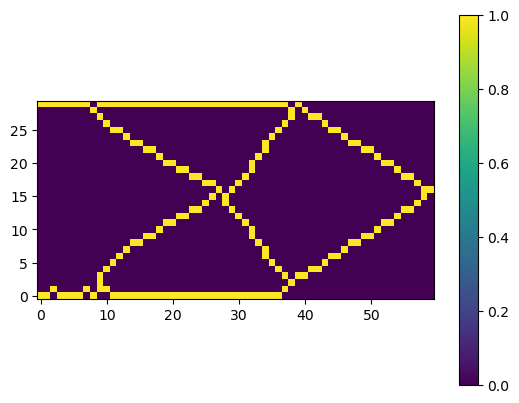

In [134]:
plt.ion()
fig, ax = plt.subplots()
im = ax.imshow(env.reshape(shrunk_design), cmap='viridis', origin='lower', vmin=0, vmax=1)
fig.colorbar(im, ax=ax)
plt.ioff()
plt.show()

In [135]:
import numpy as np
from skimage.morphology import skeletonize
from scipy.ndimage import convolve

from skimage.morphology import skeletonize
from skimage.graph import route_through_array
import numpy as np
from collections import defaultdict, deque

from skimage.morphology import skeletonize
from scipy.ndimage import convolve
from collections import defaultdict, deque
import numpy as np

def build_critical_graph_bfs(skeleton, critical_points):
    H, W = skeleton.shape
    critical_set = {tuple(pt) for pt in critical_points}
    n_points = len(critical_points)

    coord_to_idx = {tuple(critical_points[i]): i for i in range(n_points)}

    connections = defaultdict(set)

    neighbors = [(-1, -1), (-1, 0), (-1, 1),
                 (0, -1),          (0, 1),
                 (1, -1),  (1, 0),  (1, 1)]

    for idx, start in enumerate(critical_points):
        sy, sx = start
        visited = np.zeros((H, W), dtype=bool)
        queue = deque()
        queue.append((sy, sx, None))  # (y, x, prev_point)

        while queue:
            y, x, prev = queue.popleft()
            if visited[y, x]:
                continue
            visited[y, x] = True

            if (y, x) in coord_to_idx and (y, x) != (sy, sx):
                target_idx = coord_to_idx[(y, x)]
                connections[idx].add(target_idx)
                continue

            for dy, dx in neighbors:
                ny, nx = y + dy, x + dx
                if 0 <= ny < H and 0 <= nx < W and skeleton[ny, nx] and not visited[ny, nx]:
                    queue.append((ny, nx, (y, x)))

    return connections

def extract_critical_points(binary_design):
    skeleton = skeletonize(binary_design > 0).astype(np.uint8)
    
    kernel = np.ones((3,3), dtype=np.uint8)
    neighbor_count = convolve(skeleton, kernel, mode='constant', cval=0)
    
    end_points_mask = np.logical_and(skeleton==1, neighbor_count==2)
    
    branch_points_mask = np.logical_and(skeleton==1, neighbor_count >= 4)
    
    end_points = np.argwhere(end_points_mask)
    branch_points = np.argwhere(branch_points_mask)

    critical_points = np.vstack([end_points, branch_points])
    all_points_raw = np.vstack([critical_points, fixed_points]) if len(critical_points) > 0 else fixed_points
    all_points = np.array(list(set(tuple(pt) for pt in all_points_raw)))


    connections = build_critical_graph_bfs(skeleton, all_points)
    
    return all_points, connections

In [136]:
# shrunk_design
all_points, connections = extract_critical_points(shrunk_design)

print("points num:", len(all_points))

points num: 13


In [137]:
connections

defaultdict(set,
            {0: {12},
             1: {4, 5, 6},
             2: {3, 5, 11},
             3: {2},
             4: {1, 6, 8},
             5: {1, 2, 10},
             6: {1, 4},
             7: {9, 11, 12},
             8: {4, 9, 10},
             9: {7, 8, 12},
             10: {5, 8, 11},
             11: {2, 7, 10},
             12: {0, 7, 9}})

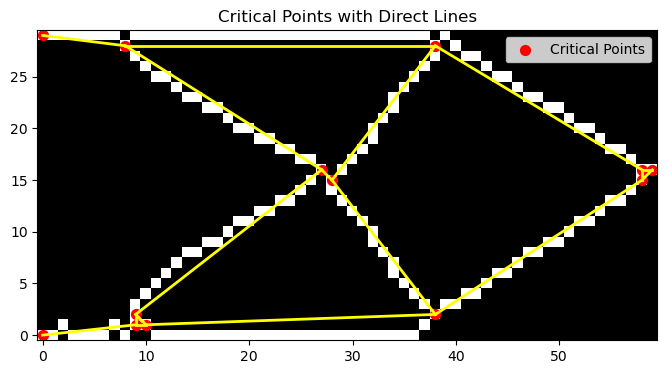

In [138]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.imshow(shrunk_design, cmap='gray', origin='lower')

ys, xs = all_points[:,0], all_points[:,1]

plt.scatter(xs, ys, c='red', s=50, label='Critical Points')

drawn_edges = set()
for i, neighbors in connections.items():
    y1, x1 = all_points[i]
    for j in neighbors:
        if (j,i) in drawn_edges:
            continue
        y2, x2 = all_points[j]
        plt.plot([x1, x2], [y1, y2], 'yellow', linewidth=2)
        drawn_edges.add((i,j))

plt.legend()
plt.title("Critical Points with Direct Lines")
plt.show()

In [139]:
def collapse_close_points(all_points, connections, fixed_mask=None, distance_threshold=5.0):
    n_points = len(all_points)
    
    if fixed_mask is not None:
        is_fixed = [fixed_mask[pt[0], pt[1]] > 0 for pt in all_points]
    else:
        is_fixed = [False] * n_points
    
    points_array = np.array(all_points)
    dist_matrix = np.sqrt(((points_array[:, np.newaxis, :] - points_array[np.newaxis, :, :]) ** 2).sum(axis=2))
    
    parent = list(range(n_points))
    
    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x
    
    def union(x, y):
        rx, ry = find(x), find(y)
        if rx != ry:
            parent[ry] = rx
    
    for i in range(n_points):
        for j in range(i + 1, n_points):
            if dist_matrix[i, j] < distance_threshold:
                if is_fixed[i] and is_fixed[j]:
                    continue
                union(i, j)
    
    groups = defaultdict(list)
    for i in range(n_points):
        root = find(i)
        groups[root].append(i)
    
    merged_points = []
    merge_map = {}
    
    for root, indices in groups.items():
        fixed_in_group = [i for i in indices if is_fixed[i]]
        
        if len(fixed_in_group) > 0:
            keep_idx = fixed_in_group[0]
            merged_points.append(all_points[keep_idx])
            for idx in indices:
                merge_map[idx] = len(merged_points) - 1
        elif len(indices) == 1:
            merged_points.append(all_points[indices[0]])
            merge_map[indices[0]] = len(merged_points) - 1
        else:
            centroid = np.mean([all_points[i] for i in indices], axis=0)
            centroid = (int(round(centroid[0])), int(round(centroid[1])))
            merged_points.append(centroid)
            for idx in indices:
                merge_map[idx] = len(merged_points) - 1
    
    merged_connections = defaultdict(set)
    for i, neighbors in connections.items():
        if i not in merge_map:
            continue
        merged_i = merge_map[i]
        for j in neighbors:
            if j not in merge_map:
                continue
            merged_j = merge_map[j]
            if merged_i != merged_j:
                merged_connections[merged_i].add(merged_j)
    
    all_points_merged = np.array(merged_points) if merged_points else np.empty((0, 2), dtype=int)
    
    return all_points_merged, merged_connections

def collapse_close_points_iterative(all_points, connections, fixed_mask=None, distance_threshold=5.0, max_iterations=100):
    current_points = all_points.copy()
    current_connections = {k: set(v) for k, v in connections.items()}
    points_removed_per_iter = []
    
    for iteration in range(max_iterations):
        prev_count = len(current_points)
        
        current_points, current_connections = collapse_close_points(
            current_points, 
            current_connections, 
            fixed_mask=fixed_mask, 
            distance_threshold=distance_threshold
        )
        
        removed = prev_count - len(current_points)
        points_removed_per_iter.append(removed)
        
        if removed == 0:
            print(f"completeted at itr {iteration + 1}")
            break
        
        print(f"itr {iteration + 1}: removed {removed} points")
    
    return current_points, current_connections

all_points_merged, connections_merged = collapse_close_points_iterative(
    all_points, 
    connections, 
    fixed_mask=fixed_mask, 
    distance_threshold=distance
)

print(f"original points: {len(all_points)}")
print(f"points after merge: {len(all_points_merged)}")
print(f"original connection: {len(connections)}")
print(f"connection after merge: {len(connections_merged)}")

itr 1: removed 7 points
completeted at itr 2
original points: 13
points after merge: 6
original connection: 13
connection after merge: 6


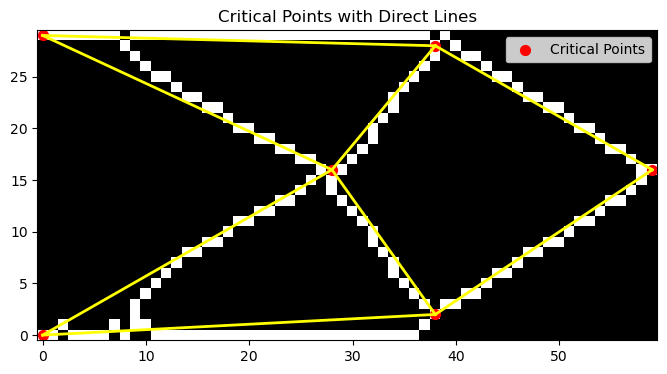

In [140]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.imshow(shrunk_design, cmap='gray', origin='lower')

ys, xs = all_points_merged[:,0], all_points_merged[:,1]

plt.scatter(xs, ys, c='red', s=50, label='Critical Points')

drawn_edges = set()
for i, neighbors in connections_merged.items():
    y1, x1 = all_points_merged[i]
    for j in neighbors:
        if (j,i) in drawn_edges:
            continue
        y2, x2 = all_points_merged[j]
        plt.plot([x1, x2], [y1, y2], 'yellow', linewidth=2)
        drawn_edges.add((i,j))

plt.legend()
plt.title("Critical Points with Direct Lines")
plt.show()

In [141]:
all_points_merged

array([[ 0,  0],
       [16, 59],
       [29,  0],
       [28, 38],
       [ 2, 38],
       [16, 28]])